IMPORT LIBRARIES

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

LOAD DATASET

In [30]:
# Load the data
col_mat_nuw_df = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/col_mat_nuw_output.csv", names=["HCHO reading", "Location", "Current Date", "Next Date"])
mon_kur_jaf_df = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/mon_kur_jaf_output.csv", names=["HCHO reading", "Location", "Current Date", "Next Date"])
kan_df = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/kan_output.csv", names=["HCHO reading", "Location", "Current Date", "Next Date"])

# Concatenate all datasets
data = pd.concat([col_mat_nuw_df, mon_kur_jaf_df, kan_df])

# Check for missing values in "HCHO reading" column
print("Number of missing values:", data["HCHO reading"].isnull().sum())
print(data.head())

data.to_csv('concat_dataset.csv', index=False)

Number of missing values: 4864
   HCHO reading        Location Current Date   Next Date
0      0.000197  Colombo Proper   2019-01-01  2019-01-02
1      0.000263  Colombo Proper   2019-01-02  2019-01-03
2      0.000099  Colombo Proper   2019-01-03  2019-01-04
3      0.000210  Colombo Proper   2019-01-04  2019-01-05
4      0.000179  Colombo Proper   2019-01-05  2019-01-06


DATA PREPROCESSING

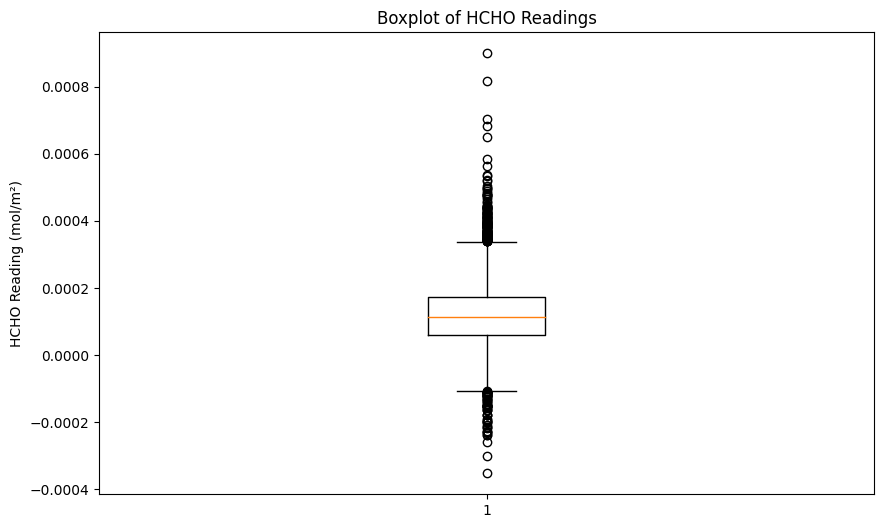

In [31]:
# Remove rows with missing values
data_cleaned = data.dropna(subset=["HCHO reading"])

# Plot boxplot after removing missing values
plt.figure(figsize=(10, 6))
plt.boxplot(data_cleaned["HCHO reading"])
plt.title("Boxplot of HCHO Readings")
plt.ylabel("HCHO Reading (mol/m²)")
plt.show()

In [32]:
# # Remove outliers using IQR method
# Q1 = data_cleaned["HCHO reading"].quantile(0.25)
# Q3 = data_cleaned["HCHO reading"].quantile(0.75)
# IQR = Q3 - Q1

# # Define upper and lower bounds
# lower_bound = Q1 - 1.5 * IQR
# upper_bound = Q3 + 1.5 * IQR

# # Filter data based on bounds
# data_cleaned = data_cleaned[(data_cleaned["HCHO reading"] >= lower_bound) & (data_cleaned["HCHO reading"] <= upper_bound)]

# # Check the shape of the cleaned data
# print("Shape of original data:", data.shape)
# print("Shape of cleaned data:", data_cleaned.shape)


In [33]:
# # Plot boxplot after removing outliers
# plt.figure(figsize=(10, 6))
# plt.boxplot(data_cleaned["HCHO reading"])
# plt.title("Boxplot of HCHO Readings (Outliers Removed)")
# plt.ylabel("HCHO Reading (mol/m²)")
# plt.show()

In [34]:
# Convert date columns to datetime format
data_cleaned["Current Date"] = pd.to_datetime(data_cleaned["Current Date"])
data_cleaned["Next Date"] = pd.to_datetime(data_cleaned["Next Date"])

# Remove duplicate rows
data_cleaned = data_cleaned.drop_duplicates()

# Standardize location names (e.g., convert to lowercase)
data_cleaned["Location"] = data_cleaned["Location"].str.lower()

<ipython-input-34-1a03a4387787>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned["Current Date"] = pd.to_datetime(data_cleaned["Current Date"])
<ipython-input-34-1a03a4387787>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned["Next Date"] = pd.to_datetime(data_cleaned["Next Date"])


In [35]:
print(data_cleaned.head())

   HCHO reading        Location Current Date  Next Date
0      0.000197  colombo proper   2019-01-01 2019-01-02
1      0.000263  colombo proper   2019-01-02 2019-01-03
2      0.000099  colombo proper   2019-01-03 2019-01-04
3      0.000210  colombo proper   2019-01-04 2019-01-05
4      0.000179  colombo proper   2019-01-05 2019-01-06


                      count      mean       std       min       25%       50%  \
Location                                                                        
bibile, monaragala   1131.0  0.000126  0.000094 -0.000239  0.000069  0.000125   
colombo proper       1339.0  0.000159  0.000099 -0.000229  0.000093  0.000151   
deniyaya, matara      979.0  0.000092  0.000097 -0.000259  0.000037  0.000081   
jaffna proper        1461.0  0.000109  0.000078 -0.000352  0.000063  0.000102   
kandy proper         1033.0  0.000106  0.000092 -0.000300  0.000050  0.000106   
kurunegala proper    1234.0  0.000134  0.000087 -0.000157  0.000078  0.000127   
nuwara eliya proper   741.0  0.000088  0.000084 -0.000179  0.000034  0.000082   

                          75%       max  
Location                                 
bibile, monaragala   0.000185  0.000535  
colombo proper       0.000221  0.000650  
deniyaya, matara     0.000139  0.000900  
jaffna proper        0.000146  0.000584  
kandy proper      

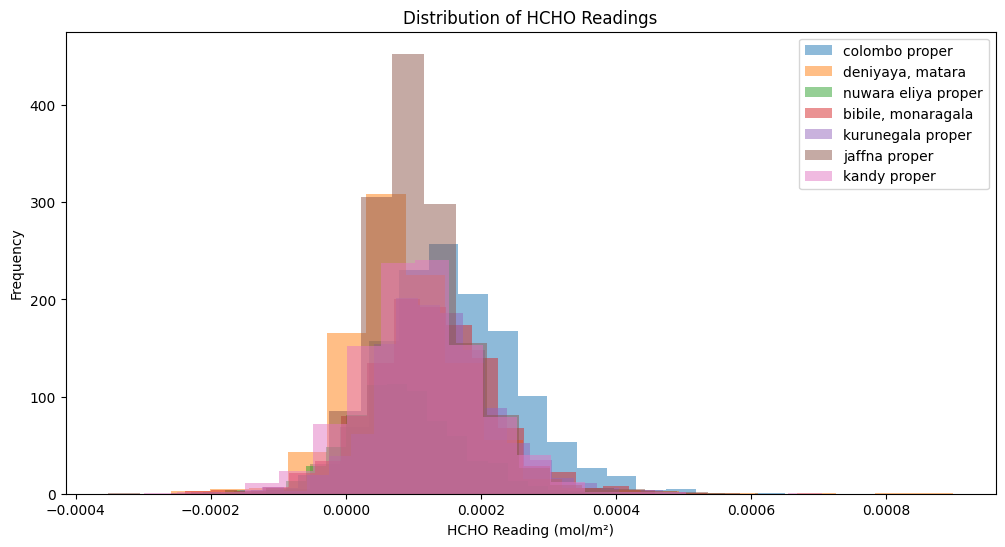

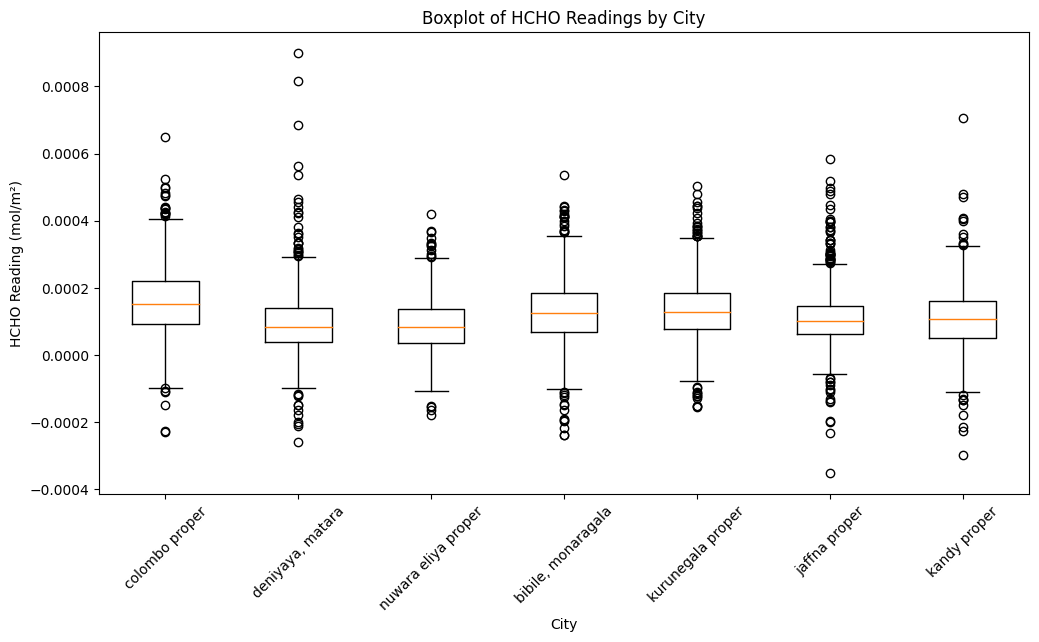

In [36]:
# Descriptive statistics
summary_stats = data_cleaned.groupby("Location")["HCHO reading"].describe()
print(summary_stats)

# Visualization - Histograms
plt.figure(figsize=(12, 6))
for city in data_cleaned["Location"].unique():
    plt.hist(data_cleaned[data_cleaned["Location"] == city]["HCHO reading"], bins=20, alpha=0.5, label=city)
plt.title("Distribution of HCHO Readings")
plt.xlabel("HCHO Reading (mol/m²)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

# Visualization - Boxplot
plt.figure(figsize=(12, 6))
plt.boxplot([data_cleaned[data_cleaned["Location"] == city]["HCHO reading"] for city in data_cleaned["Location"].unique()],
            labels=data_cleaned["Location"].unique())
plt.title("Boxplot of HCHO Readings by City")
plt.xlabel("City")
plt.ylabel("HCHO Reading (mol/m²)")
plt.xticks(rotation=45)
plt.show()

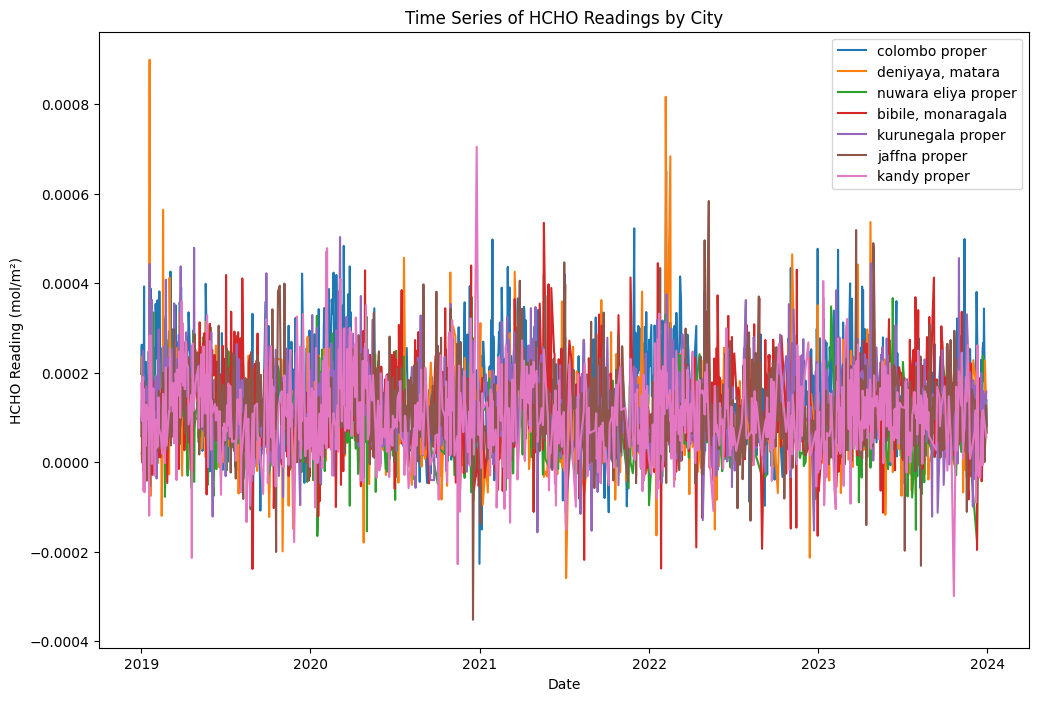

In [37]:
import seaborn as sns

# Convert 'Current Date' to datetime format
data_cleaned['Current Date'] = pd.to_datetime(data_cleaned['Current Date'])

# Plot time series graphs for each city
plt.figure(figsize=(12, 8))
for city in data_cleaned['Location'].unique():
    sns.lineplot(data=data_cleaned[data_cleaned['Location'] == city], x='Current Date', y='HCHO reading', label=city)
plt.title('Time Series of HCHO Readings by City')
plt.xlabel('Date')
plt.ylabel('HCHO Reading (mol/m²)')
plt.legend()
plt.show()


WEATHER DATA FOR COLOMBO, KURUNEGALA, NUWARA ELIYA

In [38]:
# Load weather data for Colombo
colombo_weather = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/ColomboDailyPrecipTempDataCSV.csv", header=0, names=["Station", "Location", "Date", "PRCP", "TEMPAVG", "TEMPMAX", "TEMPMIN"])

# Load weather data for Kurunegala
kurunegala_weather = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/KurunegalaDailyPrecipTempDataCSV.csv", header=0, names=["Station", "Location", "Date", "PRCP", "TEMPAVG", "TEMPMAX", "TEMPMIN"])

# Load weather data for Nuwara Eliya
nuwara_eliya_weather = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/NuwaraEliyaDailyPrecipTempCSV.csv", header=0, names=["Station", "Location", "Date", "PRCP", "TEMPAVG", "TEMPMAX", "TEMPMIN"])

print(colombo_weather.head())
print("Shape of original data:", colombo_weather.shape)

       Station     Location      Date  PRCP  TEMPAVG  TEMPMAX  TEMPMIN
0  CEM00043466  COLOMBO, CE  1/1/2019   0.0     27.5     31.7     23.4
1  CEM00043466  COLOMBO, CE  1/2/2019   0.0     25.8      NaN     23.1
2  CEM00043466  COLOMBO, CE  1/3/2019   0.0     27.1     32.1     23.1
3  CEM00043466  COLOMBO, CE  1/4/2019   0.0     27.1     32.6     22.5
4  CEM00043466  COLOMBO, CE  1/5/2019   0.0     27.2     32.3     23.5
Shape of original data: (1765, 7)


In [39]:
# Handle missing values
colombo_weather.dropna(inplace=True)
kurunegala_weather.dropna(inplace=True)
nuwara_eliya_weather.dropna(inplace=True)

# Convert date columns to datetime format
colombo_weather['Date'] = pd.to_datetime(colombo_weather['Date'])
kurunegala_weather['Date'] = pd.to_datetime(kurunegala_weather['Date'])
nuwara_eliya_weather['Date'] = pd.to_datetime(nuwara_eliya_weather['Date'])

# Check for duplicates
print("Duplicates in Colombo weather data:", colombo_weather.duplicated().sum())
print("Duplicates in Kurunegala weather data:", kurunegala_weather.duplicated().sum())
print("Duplicates in Nuwara Eliya weather data:", nuwara_eliya_weather.duplicated().sum())

# Remove duplicates
colombo_weather.drop_duplicates(inplace=True)
kurunegala_weather.drop_duplicates(inplace=True)
nuwara_eliya_weather.drop_duplicates(inplace=True)

colombo_weather["Location"] = colombo_weather["Location"].str.lower()
kurunegala_weather["Location"] = kurunegala_weather["Location"].str.lower()
nuwara_eliya_weather["Location"] = nuwara_eliya_weather["Location"].str.lower()

print(colombo_weather.head())
print(kurunegala_weather.head())
print(nuwara_eliya_weather.head())

Duplicates in Colombo weather data: 0
Duplicates in Kurunegala weather data: 0
Duplicates in Nuwara Eliya weather data: 0
       Station     Location       Date  PRCP  TEMPAVG  TEMPMAX  TEMPMIN
0  CEM00043466  colombo, ce 2019-01-01   0.0     27.5     31.7     23.4
2  CEM00043466  colombo, ce 2019-01-03   0.0     27.1     32.1     23.1
3  CEM00043466  colombo, ce 2019-01-04   0.0     27.1     32.6     22.5
4  CEM00043466  colombo, ce 2019-01-05   0.0     27.2     32.3     23.5
5  CEM00043466  colombo, ce 2019-01-06   0.0     27.4     30.9     22.8
       Station        Location       Date  PRCP  TEMPAVG  TEMPMAX  TEMPMIN
1  CEM00043441  kurunegala, ce 2019-01-03   0.0     27.4     30.5     21.9
2  CEM00043441  kurunegala, ce 2019-01-04   0.0     28.4     31.1     20.8
3  CEM00043441  kurunegala, ce 2019-01-05   0.0     28.7     32.1     18.5
4  CEM00043441  kurunegala, ce 2019-01-06   0.0     28.0     31.0     21.5
5  CEM00043441  kurunegala, ce 2019-01-07   0.0     26.9     31.5     2

In [40]:
print("Shape of cleaned data:", colombo_weather.shape)

Shape of cleaned data: (1277, 7)


In [41]:
print(data_cleaned.head())

   HCHO reading        Location Current Date  Next Date
0      0.000197  colombo proper   2019-01-01 2019-01-02
1      0.000263  colombo proper   2019-01-02 2019-01-03
2      0.000099  colombo proper   2019-01-03 2019-01-04
3      0.000210  colombo proper   2019-01-04 2019-01-05
4      0.000179  colombo proper   2019-01-05 2019-01-06


In [42]:
location_mapping = {
    "colombo proper": "colombo, ce",
    "kurunegala proper": "kurunegala, ce",
    "nuwara eliya proper": "nuwara eliya, ce"
}

data_cleaned['Location'] = data_cleaned['Location'].map(location_mapping)

In [43]:
# Merge weather data with HCHO dataset
merged_colombo = pd.merge(data_cleaned[data_cleaned["Location"] == "colombo, ce"], colombo_weather, left_on="Current Date", right_on="Date", how="left")
merged_kurunegala = pd.merge(data_cleaned[data_cleaned["Location"] == "kurunegala, ce"], kurunegala_weather, left_on="Current Date", right_on="Date", how="left")
merged_nuwara_eliya = pd.merge(data_cleaned[data_cleaned["Location"] == "nuwara eliya, ce"], nuwara_eliya_weather, left_on="Current Date", right_on="Date", how="left")

In [44]:
print("COLOMBO")
print(merged_colombo.head())
print("\nKURUNEGALA")
print(merged_kurunegala.head())
print("\nNUWARA")
print(merged_nuwara_eliya.head())

COLOMBO
   HCHO reading   Location_x Current Date  Next Date      Station  \
0      0.000197  colombo, ce   2019-01-01 2019-01-02  CEM00043466   
1      0.000263  colombo, ce   2019-01-02 2019-01-03          NaN   
2      0.000099  colombo, ce   2019-01-03 2019-01-04  CEM00043466   
3      0.000210  colombo, ce   2019-01-04 2019-01-05  CEM00043466   
4      0.000179  colombo, ce   2019-01-05 2019-01-06  CEM00043466   

    Location_y       Date  PRCP  TEMPAVG  TEMPMAX  TEMPMIN  
0  colombo, ce 2019-01-01   0.0     27.5     31.7     23.4  
1          NaN        NaT   NaN      NaN      NaN      NaN  
2  colombo, ce 2019-01-03   0.0     27.1     32.1     23.1  
3  colombo, ce 2019-01-04   0.0     27.1     32.6     22.5  
4  colombo, ce 2019-01-05   0.0     27.2     32.3     23.5  

KURUNEGALA
   HCHO reading      Location_x Current Date  Next Date      Station  \
0      0.000088  kurunegala, ce   2019-01-01 2019-01-02          NaN   
1      0.000137  kurunegala, ce   2019-01-02 2019-01-03

In [45]:
# Handle missing values
merged_colombo.dropna(inplace=True)
merged_kurunegala.dropna(inplace=True)
merged_nuwara_eliya.dropna(inplace=True)

In [46]:
print("COLOMBO")
print(merged_colombo.head())
print("\nKURUNEGALA")
print(merged_kurunegala.head())
print("\nNUWARA")
print(merged_nuwara_eliya.head())

COLOMBO
   HCHO reading   Location_x Current Date  Next Date      Station  \
0      0.000197  colombo, ce   2019-01-01 2019-01-02  CEM00043466   
2      0.000099  colombo, ce   2019-01-03 2019-01-04  CEM00043466   
3      0.000210  colombo, ce   2019-01-04 2019-01-05  CEM00043466   
4      0.000179  colombo, ce   2019-01-05 2019-01-06  CEM00043466   
5      0.000108  colombo, ce   2019-01-06 2019-01-07  CEM00043466   

    Location_y       Date  PRCP  TEMPAVG  TEMPMAX  TEMPMIN  
0  colombo, ce 2019-01-01   0.0     27.5     31.7     23.4  
2  colombo, ce 2019-01-03   0.0     27.1     32.1     23.1  
3  colombo, ce 2019-01-04   0.0     27.1     32.6     22.5  
4  colombo, ce 2019-01-05   0.0     27.2     32.3     23.5  
5  colombo, ce 2019-01-06   0.0     27.4     30.9     22.8  

KURUNEGALA
   HCHO reading      Location_x Current Date  Next Date      Station  \
2      0.000148  kurunegala, ce   2019-01-03 2019-01-04  CEM00043441   
3     -0.000002  kurunegala, ce   2019-01-04 2019-01-05

In [47]:
print("COLOMBO")
print(merged_colombo.shape)
print("\nKURUNEGALA")
print(merged_kurunegala.shape)
print("\nNUWARA")
print(merged_nuwara_eliya.shape)

COLOMBO
(958, 11)

KURUNEGALA
(900, 11)

NUWARA
(481, 11)


In [48]:
print("Duplicates in Colombo weather data:", merged_colombo.duplicated().sum())
print("Duplicates in Kurunegala weather data:", merged_kurunegala.duplicated().sum())
print("Duplicates in Nuwara Eliya weather data:", merged_nuwara_eliya.duplicated().sum())

Duplicates in Colombo weather data: 0
Duplicates in Kurunegala weather data: 0
Duplicates in Nuwara Eliya weather data: 0


In [49]:
merged_colombo.to_csv('merged_colombo.csv', index=False)
merged_kurunegala.to_csv('merged_kurunegala.csv', index=False)
merged_nuwara_eliya.to_csv('merged_nuwara_eliya.csv', index=False)

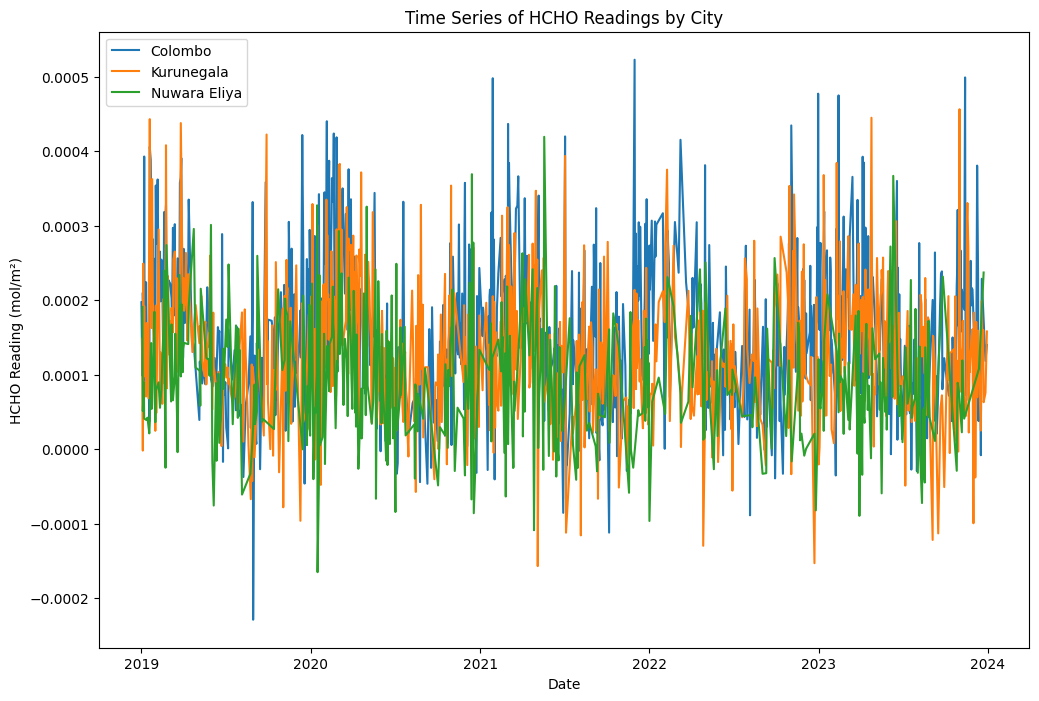

In [50]:
plt.figure(figsize=(12, 8))

# Plot time series graphs for each city
for city_data, city_name in zip([merged_colombo, merged_kurunegala, merged_nuwara_eliya], ["Colombo", "Kurunegala", "Nuwara Eliya"]):
    sns.lineplot(data=city_data, x="Current Date", y="HCHO reading", label=city_name)

plt.title('Time Series of HCHO Readings by City')
plt.xlabel('Date')
plt.ylabel('HCHO Reading (mol/m²)')
plt.legend()
plt.show()


In [51]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
import numpy as np

# merged_colombo['Date'] = pd.to_datetime(merged_colombo['Date'])
merged_colombo.set_index('Current Date', inplace=True)

# Define and fit the ARIMA model
# You need to specify the order (p, d, q) of the ARIMA model
# This example uses p=1 (autoregressive order), d=1 (differencing order), q=1 (moving average order)
model = ARIMA(merged_colombo['HCHO reading'], order=(5,1,0))
result = model.fit()

# Print model summary
print(result.summary())

# Forecast the next n steps (change 'n' as needed)
n_steps = 10
forecast = result.forecast(steps=n_steps)

# Print forecast
print(forecast)

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:           HCHO reading   No. Observations:                  958
Model:                 ARIMA(5, 1, 0)   Log Likelihood                7561.533
Date:                Thu, 11 Apr 2024   AIC                         -15111.066
Time:                        19:03:36   BIC                         -15081.883
Sample:                             0   HQIC                        -15099.951
                                - 958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7360   1.08e-19  -6.81e+18      0.000      -0.736      -0.736
ar.L2         -0.5613   6.92e-19  -8.11e+17      0.000      -0.561      -0.561
ar.L3         -0.3855   5.81e-19  -6.64e+17      0.0

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


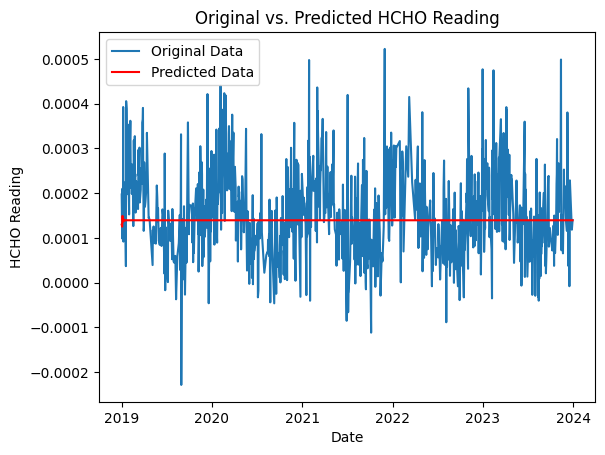

In [52]:
# Plotting the original time series data
plt.plot(merged_colombo.index, merged_colombo['HCHO reading'], label='Original Data')

# Plotting the predicted values from the ARIMA model
plt.plot(merged_colombo.index, result.forecast(len(merged_colombo)), color='red', label='Predicted Data')

# Adding labels and title
plt.xlabel('Date')
plt.ylabel('HCHO Reading')
plt.title('Original vs. Predicted HCHO Reading')
plt.legend()

# Display the plot
plt.show()

In [53]:
# merged_colombo['Date'] = pd.to_datetime(merged_colombo['Date'])
merged_kurunegala.set_index('Current Date', inplace=True)

# Define and fit the ARIMA model
# You need to specify the order (p, d, q) of the ARIMA model
# This example uses p=1 (autoregressive order), d=1 (differencing order), q=1 (moving average order)
model = ARIMA(merged_kurunegala['HCHO reading'], order=(4,0,4))
result = model.fit()

# Print model summary
print(result.summary())

# Forecast the next n steps (change 'n' as needed)
n_steps = 10
forecast = result.forecast(steps=n_steps)

# Print forecast
print(forecast)

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:           HCHO reading   No. Observations:                  900
Model:                 ARIMA(4, 0, 4)   Log Likelihood                7186.752
Date:                Thu, 11 Apr 2024   AIC                         -14353.503
Time:                        19:03:38   BIC                         -14305.479
Sample:                             0   HQIC                        -14335.158
                                - 900                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0001   7.76e-06     16.825      0.000       0.000       0.000
ar.L1          0.5893   3.25e-10   1.82e+09      0.000       0.589       0.589
ar.L2         -0.2689   4.98e-11   -5.4e+09      0.0

/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


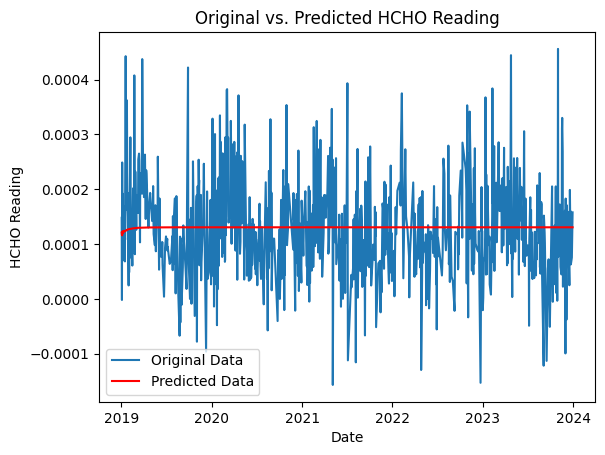

In [54]:
# Plotting the original time series data
plt.plot(merged_kurunegala.index, merged_kurunegala['HCHO reading'], label='Original Data')

# Plotting the predicted values from the ARIMA model
plt.plot(merged_kurunegala.index, result.forecast(len(merged_kurunegala)), color='red', label='Predicted Data')

# Adding labels and title
plt.xlabel('Date')
plt.ylabel('HCHO Reading')
plt.title('Original vs. Predicted HCHO Reading')
plt.legend()

# Display the plot
plt.show()

In [55]:
# merged_colombo['Date'] = pd.to_datetime(merged_colombo['Date'])
merged_nuwara_eliya.set_index('Current Date', inplace=True)

# Define and fit the ARIMA model
# You need to specify the order (p, d, q) of the ARIMA model
# This example uses p=1 (autoregressive order), d=1 (differencing order), q=1 (moving average order)
model = ARIMA(merged_nuwara_eliya['HCHO reading'], order=(4,0,4))
result = model.fit()

# Print model summary
print(result.summary())

# Forecast the next n steps (change 'n' as needed)
n_steps = 10
forecast = result.forecast(steps=n_steps)

# Print forecast
print(forecast)

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:           HCHO reading   No. Observations:                  481
Model:                 ARIMA(4, 0, 4)   Log Likelihood                3838.090
Date:                Thu, 11 Apr 2024   AIC                          -7656.181
Time:                        19:03:43   BIC                          -7614.422
Sample:                             0   HQIC                         -7639.768
                                - 481                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       8.777e-05   4.51e-06     19.480      0.000    7.89e-05    9.66e-05
ar.L1          0.1397   5.79e-11   2.41e+09      0.000       0.140       0.140
ar.L2         -0.0362   1.23e-11  -2.93e+09      0.0

/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


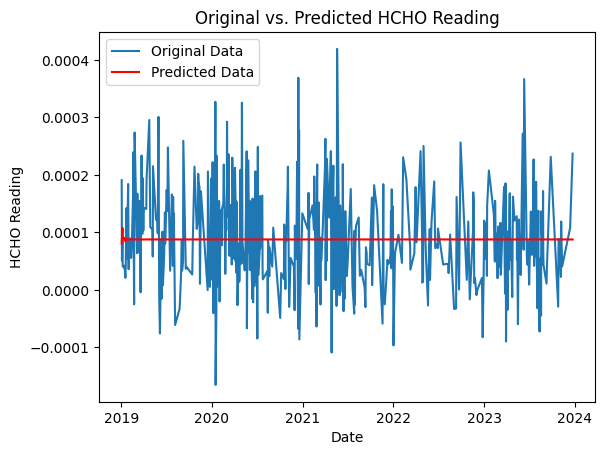

In [56]:
# Plotting the original time series data
plt.plot(merged_nuwara_eliya.index, merged_nuwara_eliya['HCHO reading'], label='Original Data')

# Plotting the predicted values from the ARIMA model
plt.plot(merged_nuwara_eliya.index, result.forecast(len(merged_nuwara_eliya)), color='red', label='Predicted Data')

# Adding labels and title
plt.xlabel('Date')
plt.ylabel('HCHO Reading')
plt.title('Original vs. Predicted HCHO Reading')
plt.legend()

# Display the plot
plt.show()